In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install -r requirements.txt
!pip install ultralytics supervision

ERROR: Could not open requirements file: [Errno 2] No such file or directory: 'requirements.txt'
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 3.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.2/107.2 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 48.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 469.1/469.1 kB 48.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 66.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.0/204.0 kB 24.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 12.9 MB/s eta 0:00:00


In [ ]:
import os

# Tạo thư mục dự án trên Drive (thay đổi đường dẫn nếu bạn lưu ở chỗ khác)
PROJECT_DIR = "/content/drive/MyDrive/carParking"
os.makedirs(PROJECT_DIR, exist_ok=True)

# Chuyển hướng làm việc vào thư mục này
%cd {PROJECT_DIR}

# Tạo các thư mục con cần thiết
os.makedirs("models", exist_ok=True)   # Nơi chứa best.pt
os.makedirs("data", exist_ok=True)     # Nơi chứa video thật
os.makedirs("out", exist_ok=True)

/content/drive/MyDrive/carParking


In [3]:
  import cv2
  import json
  import numpy as np
  from ultralytics import YOLO

  VIDEO_PATH = "/content/drive/MyDrive/carParking/data/carParking.mp4"

  cap_init = cv2.VideoCapture(VIDEO_PATH)
  ret_init, first_frame = cap_init.read()
  cap_init.release()

  if not ret_init:
      raise Exception(f"Không đọc được video từ đường dẫn: {VIDEO_PATH}")

  # Kích thước video gốc
  orig_h, orig_w = first_frame.shape[:2]
  print(f"✓ Kích thước video gốc: {orig_w} x {orig_h}")

  # Lưu lại frame đầu tiên đúng độ phân giải gốc để làm tọa độ vẽ bounding box
  OUTPUT_PNG_PATH = "first_frame.png"
  cv2.imwrite(OUTPUT_PNG_PATH, first_frame)
  print(f"✓ Đã lưu file PNG đúng chuẩn kích thước video tại: {OUTPUT_PNG_PATH}\n")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
✓ Kích thước video gốc: 1920 x 1080
✓ Đã lưu file PNG đúng chuẩn kích thước video tại: first_frame.png



In [4]:
import json

# Đường dẫn file JSON trên Google Drive của bạn
JSON_PATH = "/content/drive/MyDrive/carParking/roboflow_output.json"

# Đọc dữ liệu từ file JSON
with open(JSON_PATH, "r") as f:
    roboflow_data = json.load(f)

# Kiểm tra nếu dữ liệu là dict chứa key "predictions" hay là một list trực tiếp
preds = roboflow_data.get("predictions", roboflow_data) if isinstance(roboflow_data, dict) else roboflow_data

slots = []
for idx, pred in enumerate(preds, start=1):
    cx = pred["x"]
    cy = pred["y"]
    w = pred["width"]
    h = pred["height"]

    # Tính 4 góc Bounding Box từ Center X, Center Y, Width, Height
    x1 = int(cx - w / 2)
    y1 = int(cy - h / 2)
    x2 = int(cx + w / 2)
    y2 = int(cy + h / 2)

    # Tạo Polygon 4 đỉnh (theo chiều kim đồng hồ)
    coords = [
        [x1, y1],  # Góc trên - trái
        [x2, y1],  # Góc trên - phải
        [x2, y2],  # Góc dưới - phải
        [x1, y2]   # Góc dưới - trái
    ]

    slots.append({
        "id": idx,
        "coordinates": coords
    })

# Lưu ra file slots.json
with open("slots.json", "w") as f:
    json.dump(slots, f, indent=2)

print(f"✅ Đã chuyển đổi thành công {len(slots)} ô đỗ sang file slots.json!")

✅ Đã chuyển đổi thành công 196 ô đỗ sang file slots.json!



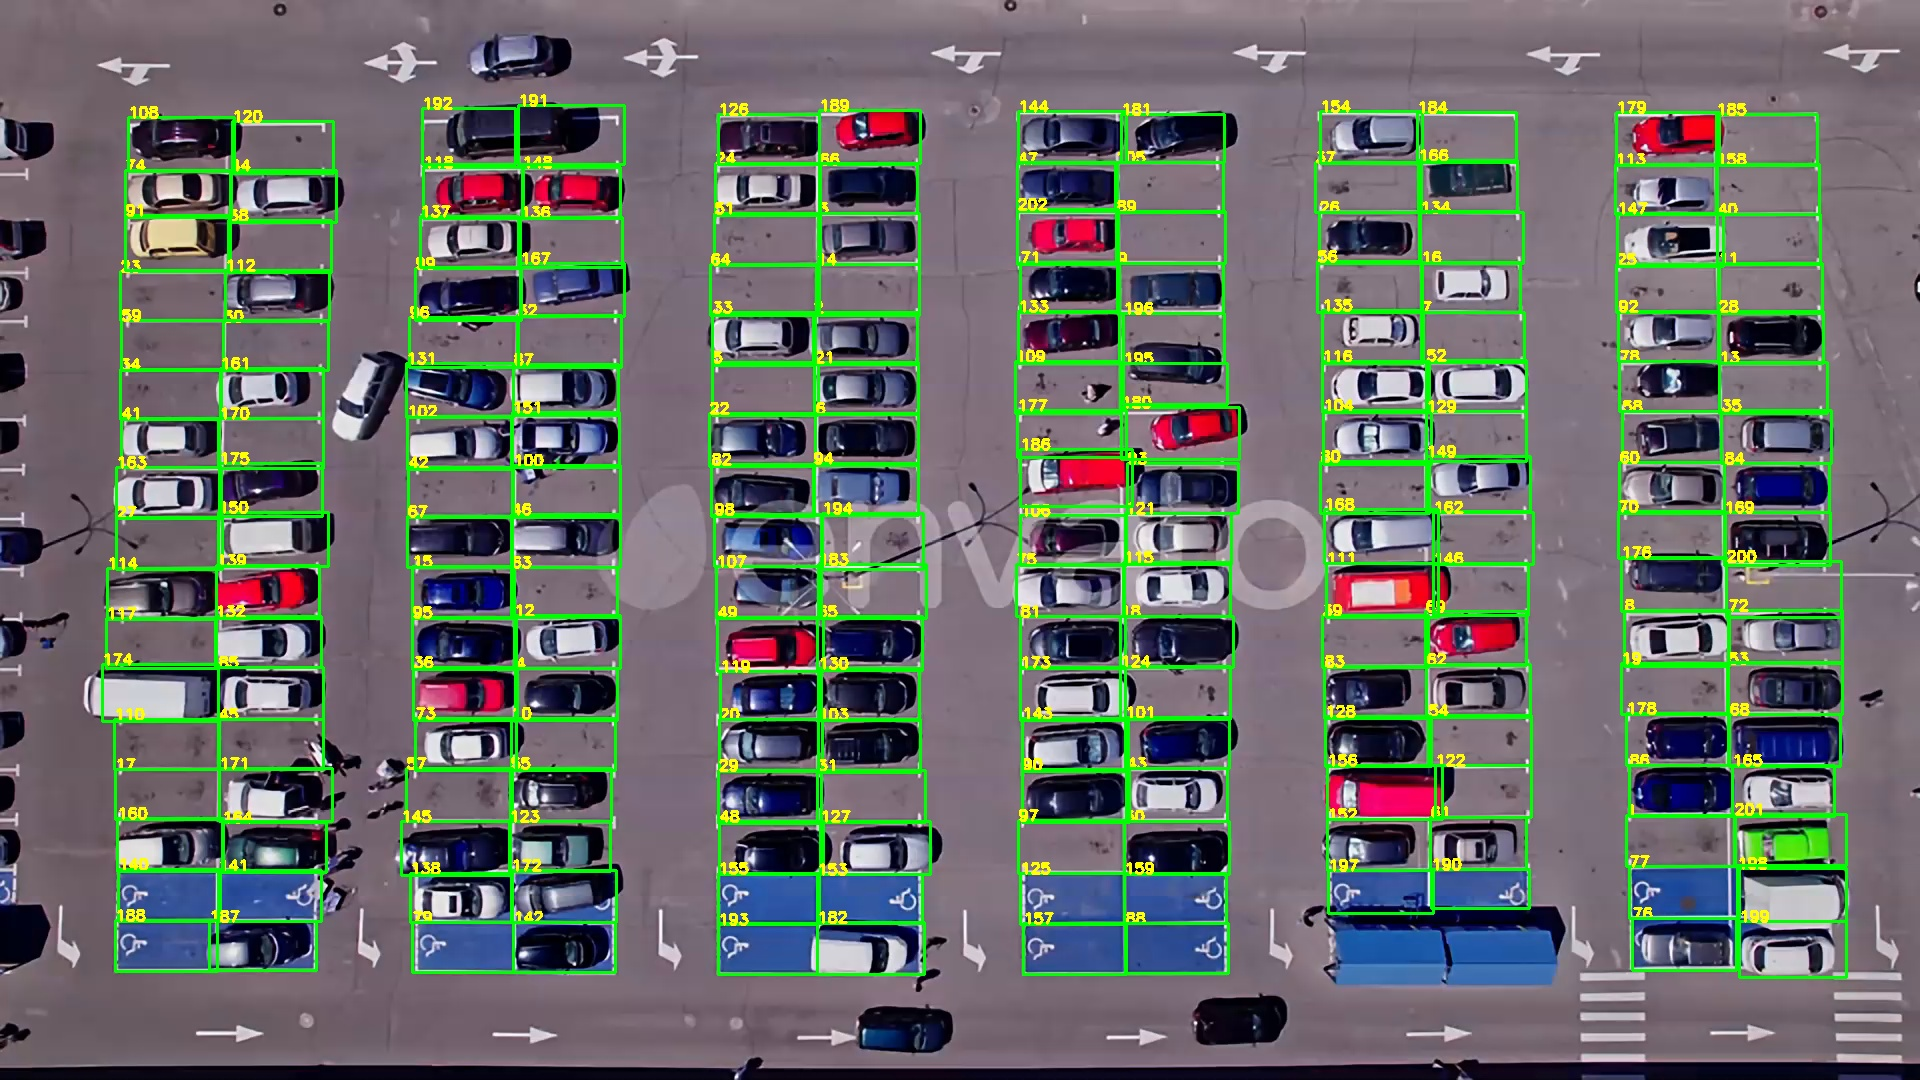

In [5]:
import cv2, json, base64
import IPython.display as display

# 1. Đường dẫn video và file slots.json vừa tạo
VIDEO_PATH = "/content/drive/MyDrive/carParking/data/carParking.mp4"  # Thay bằng tên video của bạn
SLOTS_PATH = "/content/drive/MyDrive/carParking/slots.json"

# Read frame 0
cap = cv2.VideoCapture(VIDEO_PATH)
ok, frame = cap.read()
cap.release()

if not ok:
    raise ValueError(f"Không thể đọc video tại {VIDEO_PATH}")

# Read slots
with open(SLOTS_PATH, "r") as f:
    slots = json.load(f)

# 2. Vẽ tất cả ô đỗ từ slots.json lên frame
import numpy as np

img_check = frame.copy()
for s in slots:
    pts = np.array(s["coordinates"], np.int32)
    # Vẽ viền ô đỗ màu xanh lá
    cv2.polylines(img_check, [pts], True, (0, 255, 0), 2)
    # In ID của ô đỗ
    cv2.putText(img_check, str(s["id"]), tuple(pts[0]),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 2)

# 3. Mã hóa sang Base64 và hiển thị trực tiếp trong Notebook
_, buffer = cv2.imencode('.jpg', img_check)
img_b64 = base64.b64encode(buffer).decode('utf-8')

html_code = f"""
<h3>Hình ảnh kiểm tra vị trí các ô đỗ (Tổng số: {len(slots)} ô)</h3>
<img src="data:image/jpeg;base64,{img_b64}" style="max-width: 100%; border: 2px solid #333;" />
"""
display.display(display.HTML(html_code))

In [ ]:
import json

SLOTS_PATH = "/content/drive/MyDrive/carParking/slots.json"

# 1. Nhập danh sách các ID ô đỗ bạn muốn XÓA vào đây
REMOVE_IDS = [189, 186, 119]  # Thay bằng các số ID thừa hiển thị trên hình của bạn

# 2. Đọc file slots.json
with open(SLOTS_PATH, "r") as f:
    slots = json.load(f)

print(f"Tổng số ô ban đầu: {len(slots)}")

# 3. Lọc bỏ các ô nằm trong danh sách REMOVE_IDS
filtered_slots = [s for s in slots if s["id"] not in REMOVE_IDS]

# 4. Đánh lại ID theo thứ tự liên tục 1, 2, 3... (tránh bị nhảy số)
for idx, s in enumerate(filtered_slots, start=1):
    s["id"] = idx

# 5. Lưu lại file slots.json
with open(SLOTS_PATH, "w") as f:
    json.dump(filtered_slots, f, indent=2)

print(f"✅ Đã xóa {len(slots) - len(filtered_slots)} ô đỗ có ID: {REMOVE_IDS}")
print(f"✅ Số ô đỗ còn lại: {len(filtered_slots)} (đã đánh lại ID liên tục)")

Tổng số ô ban đầu: 202
✅ Đã xóa 3 ô đỗ có ID: [189, 186, 119]
✅ Số ô đỗ còn lại: 199 (đã đánh lại ID liên tục)


Kích thước video: 1920 x 1080
Đã nạp thành công 202 ô đỗ hiện có từ /content/drive/MyDrive/carParking/slots.json



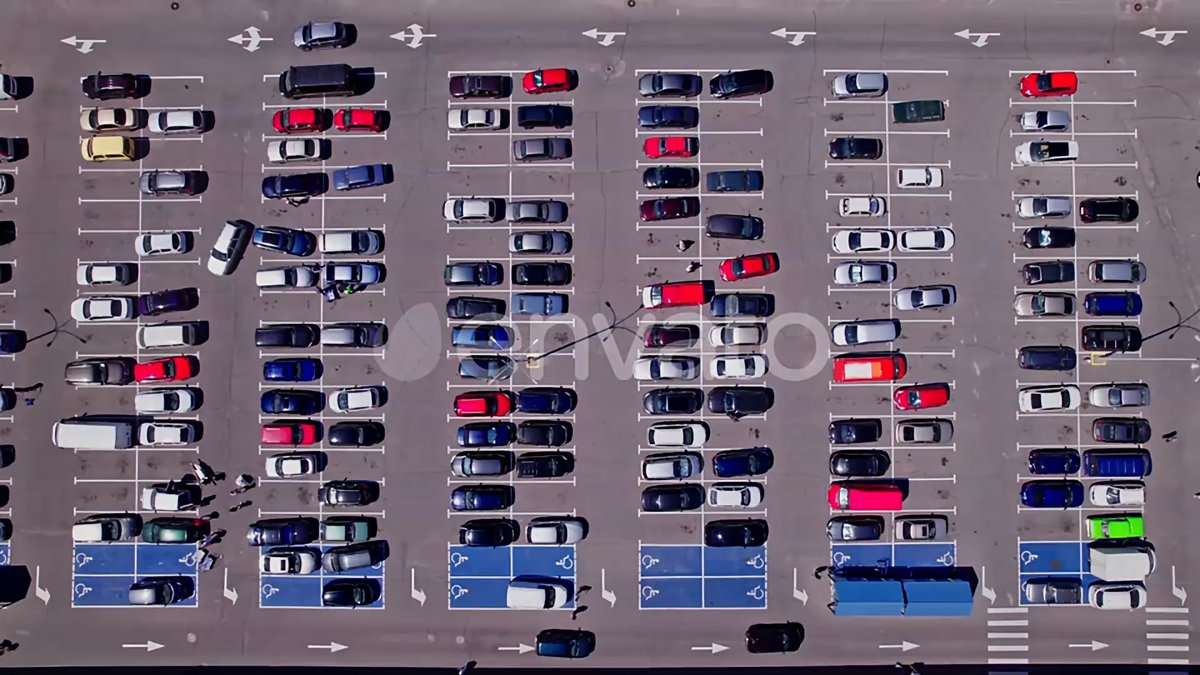


✓ ĐÃ CẬP NHẬT FILE SLOTS.JSON
Tổng số ô đỗ: 202
Đường dẫn file: /content/drive/MyDrive/carParking/slots.json


In [6]:
import cv2
import json
import base64
import os
from google.colab import output
from IPython.display import display, HTML
from PIL import Image
import io

# ============================================
# CẤU HÌNH ĐƯỜNG DẪN FILE & VIDEO
# ============================================
VIDEO_PATH = "/content/drive/MyDrive/carParking/data/carParking.mp4"   # Thay đường dẫn video thật của bạn
SLOT_FILE = "/content/drive/MyDrive/carParking/slots.json"              # File slots hiện tại cần nạp & bổ sung

# Read frame 0
cap = cv2.VideoCapture(VIDEO_PATH)
ret, frame = cap.read()
cap.release()

if not ret:
    raise Exception(f"Không đọc được video từ {VIDEO_PATH}")

original_height, original_width = frame.shape[:2]
print(f"Kích thước video: {original_width} x {original_height}")

# ============================================
# ĐỌC CÁC Ô ĐỖ ĐÃ CÓ TRONG SLOTS.JSON (NẾU CÓ)
# ============================================
existing_slots = []
if os.path.exists(SLOT_FILE):
    try:
        with open(SLOT_FILE, "r", encoding="utf-8") as f:
            existing_slots = json.load(f)
        print(f"Đã nạp thành công {len(existing_slots)} ô đỗ hiện có từ {SLOT_FILE}")
    except Exception as e:
        print(f"Lỗi đọc file slots cũ: {e}")

# Chuyển đổi frame thành Base64
frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
image = Image.fromarray(frame_rgb)

MAX_WIDTH = 1200
display_width = min(original_width, MAX_WIDTH)
display_height = int(original_height * display_width / original_width)
image_display = image.resize((display_width, display_height))

buffer = io.BytesIO()
image_display.save(buffer, format="JPEG", quality=85)
image_base64 = base64.b64encode(buffer.getvalue()).decode("utf-8")

# ============================================
# JAVASCRIPT GIAO DIỆN CLICK BỔ SUNG Ô
# ============================================
html = f"""
<div style="font-family: Arial;">

<h3>🅿️ ĐÁNH DẤU BỔ SUNG CÁC Ô ĐỖ XE CÒN THIẾU</h3>

<p>
<b>Hướng dẫn:</b> Các ô màu xanh lá đã có sẵn từ file. Để vẽ ô mới, click <b>góc thứ nhất</b> ➔ click <b>góc đối diện</b>.
</p>

<div style="margin-bottom:10px;">
<button onclick="undoLast()" style="padding:8px 15px; margin-right:5px; cursor:pointer;">
↩️ Xóa ô vừa vẽ
</button>

<button onclick="finishSlots()" style="padding:8px 15px; background-color:#28a745; color:white; border:none; border-radius:4px; cursor:pointer;">
✅ LƯU ĐÈ VÀO SLOTS.JSON
</button>
</div>

<div style="border:2px solid #333; display:inline-block; position:relative;">
<canvas id="parkingCanvas" width="{display_width}" height="{display_height}" style="cursor:crosshair;">
</canvas>
</div>

<p id="status">
Tổng số ô hiện tại: <b>{len(existing_slots)}</b> ô
</p>

<script>
const canvas = document.getElementById("parkingCanvas");
const ctx = canvas.getContext("2d");
const img = new Image();

const originalWidth = {original_width};
const originalHeight = {original_height};

const scaleX = originalWidth / canvas.width;
const scaleY = originalHeight / canvas.height;

// Nạp danh sách ô đã có sẵn từ Python
let slots = {json.dumps(existing_slots)};
let initialCount = slots.length;
let currentPoints = [];

img.onload = function() {{
    redraw();
}};

img.src = "data:image/jpeg;base64,{image_base64}";

canvas.addEventListener("click", function(event) {{
    const rect = canvas.getBoundingClientRect();
    const x = event.clientX - rect.left;
    const y = event.clientY - rect.top;

    currentPoints.push({{ x: x, y: y }});

    // Vẽ chấm tròn điểm click
    ctx.fillStyle = "yellow";
    ctx.beginPath();
    ctx.arc(x, y, 4, 0, 2 * Math.PI);
    ctx.fill();

    // Đủ 2 điểm góc ➔ Tạo ô đỗ mới
    if (currentPoints.length === 2) {{
        const p1 = currentPoints[0];
        const p2 = currentPoints[1];

        const x1 = Math.round(Math.min(p1.x, p2.x) * scaleX);
        const y1 = Math.round(Math.min(p1.y, p2.y) * scaleY);
        const x2 = Math.round(Math.max(p1.x, p2.x) * scaleX);
        const y2 = Math.round(Math.max(p1.y, p2.y) * scaleY);

        const newId = slots.length + 1;

        // Lưu dạng Polygon 4 góc tương thích với pipeline code
        slots.push({{
            "id": newId,
            "coordinates": [
                [x1, y1],
                [x2, y1],
                [x2, y2],
                [x1, y2]
            ]
        }});

        currentPoints = [];
        redraw();
    }}
}});

function redraw() {{
    ctx.drawImage(img, 0, 0, canvas.width, canvas.height);

    for (let i = 0; i < slots.length; i++) {{
        const s = slots[i];
        let x1, y1, x2, y2;

        // Xử lý tọa độ từ coordinates
        if (s.coordinates && s.coordinates.length >= 4) {{
            x1 = s.coordinates[0][0] / scaleX;
            y1 = s.coordinates[0][1] / scaleY;
            x2 = s.coordinates[2][0] / scaleX;
            y2 = s.coordinates[2][1] / scaleY;
        }} else {{
            continue;
        }}

        // Phân biệt ô cũ và ô vừa vẽ thêm bằng màu sắc
        if (i < initialCount) {{
            ctx.strokeStyle = "#00FF00"; // Màu xanh lá cho ô cũ
        }} else {{
            ctx.strokeStyle = "#FFD700"; // Màu vàng cho ô mới vẽ
        }}

        ctx.lineWidth = 2;
        ctx.strokeRect(x1, y1, x2 - x1, y2 - y1);

        // Hiển thị ID ô
        ctx.fillStyle = "yellow";
        ctx.font = "bold 16px Arial";
        ctx.fillText(s.id, x1 + 4, y1 + 18);
    }}

    document.getElementById("status").innerHTML =
        "Tổng số ô: <b>" + slots.length + "</b> (Cũ: " + initialCount + " | Mới vẽ: " + (slots.length - initialCount) + ")";
}}

function undoLast() {{
    if (slots.length <= initialCount) {{
        alert("Không thể xóa các ô cũ đã nạp sẵn!");
        return;
    }}
    slots.pop();
    currentPoints = [];
    redraw();
}}

async function finishSlots() {{
    google.colab.kernel.invokeFunction(
        'notebook.saveSlots',
        [JSON.stringify(slots, null, 2)],
        {{}}
    );

    document.getElementById("status").innerHTML =
        "✅ ĐÃ LƯU THÀNH CÔNG " + slots.length + " Ô VÀO SLOTS.JSON!";
}}
</script>
</div>
"""

# ============================================
# HÀM LƯU FILE VÀO SLOTS.JSON
# ============================================
def save_slots_from_js(slots_json):
    parking_slots = json.loads(slots_json)

    # Cập nhật đánh lại ID theo thứ tự 1..N
    for idx, s in enumerate(parking_slots, start=1):
        s["id"] = idx

    with open(SLOT_FILE, "w", encoding="utf-8") as f:
        json.dump(parking_slots, f, indent=2, ensure_ascii=False)

    print("\n================================")
    print("✓ ĐÃ CẬP NHẬT FILE SLOTS.JSON")
    print("================================")
    print("Tổng số ô đỗ:", len(parking_slots))
    print("Đường dẫn file:", SLOT_FILE)

output.register_callback("notebook.saveSlots", save_slots_from_js)
display(HTML(html))

# Kiểm tra lưới ô đỗ

In [ ]:
%%writefile overlay_slots.py
import argparse
import json
import cv2
import numpy as np

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--video", required=True)
    ap.add_argument("--slots", required=True)
    ap.add_argument("--frames", type=int, nargs="*", default=[0, 300])
    ap.add_argument("--save", default="overlay_slots.png")
    args = ap.parse_args()

    slots = json.load(open(args.slots, encoding="utf-8"))
    cap = cv2.VideoCapture(args.video)
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    W = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)); H = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    xs = [p[0] for s in slots for p in s["coordinates"]]
    ys = [p[1] for s in slots for p in s["coordinates"]]
    print(f"Video: {W}x{H}, {n} frame | {len(slots)} ô | Tọa độ x: {min(xs)}..{max(xs)}, y: {min(ys)}..{max(ys)}")

    if max(xs) > W or max(ys) > H:
        print("⚠️ CẢNH BÁO: Tọa độ ô nằm ngoài khung hình -> slots.json vẽ cho video khác resolution!")

    panels = []
    for f in args.frames:
        f = min(max(f, 0), n - 1)
        cap.set(cv2.CAP_PROP_POS_FRAMES, f)
        ok, im = cap.read()
        if not ok: continue
        for s in slots:
            cv2.polylines(im, [np.array(s["coordinates"], np.int32)], True, (0, 255, 0), 1, cv2.LINE_AA)
        cv2.putText(im, f"frame {f}", (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2)
        panels.append(im)
    cap.release()
    cv2.imwrite(args.save, np.vstack(panels) if len(panels) > 1 else panels[0])
    print(f"✅ Đã lưu hình ảnh kiểm tra tại: {args.save}")

if __name__ == "__main__":
    main()

Overwriting overlay_slots.py


In [ ]:
!python overlay_slots.py \
    --video /content/drive/MyDrive/carParking/data/carParking2.mp4 \
    --slots /content/drive/MyDrive/carParking/slots.json

Video: 3700x2082, 849 frame | 391 ô | Tọa độ x: 127..3565, y: 185..2082
✅ Đã lưu hình ảnh kiểm tra tại: overlay_slots.png


In [ ]:
!pip install lap==0.5.13


# PARKING 1

In [16]:
import sys
import os
import argparse
import csv
import json
import time
from pathlib import Path

PROJECT_PATH = "/content/drive/MyDrive/carParking"
IN_COLAB_PROJECT = os.path.exists(PROJECT_PATH)
if IN_COLAB_PROJECT:
    sys.path.append(PROJECT_PATH)
    os.chdir(PROJECT_PATH)

import cv2
import numpy as np

# Dashboard renderer tự chứa trong Cell 13 (không cần ui_modern.py)
GROUP_COLORS = [
    (255, 73, 137), (75, 190, 255), (99, 44, 255),
    (255, 90, 210), (249, 145, 45), (225, 235, 245)
]
FREE_COLOR = (55, 235, 120)
BG = (11, 16, 29)
PANEL = (20, 28, 45)
TEXT = (235, 241, 252)
MUTED = (145, 160, 185)

class Renderer:
    def __init__(self, slots, W, H, scale=1.0, groups=6, alpha=0.35, inset=1.0, line=2):
        self.slots = slots
        self.W, self.H = int(W), int(H)
        self.scale = max(float(scale), 0.1)
        self.groups = max(1, int(groups))
        self.alpha, self.inset, self.line = float(alpha), float(inset), max(1, int(line))
        self.idx = {s["id"]: i for i, s in enumerate(slots)}
        self.slot_groups = self._assign_groups()
        self.top_h, self.bottom_h, self.side_w = 72, 42, 320
        self.content_w = int(self.W * self.scale)
        self.content_h = int(self.H * self.scale)
        self.size = (self.content_w + self.side_w, self.content_h + self.top_h + self.bottom_h)

    def _assign_groups(self):
        if not self.slots:
            return {}
        centers = np.array([np.mean([p[0] for p in s["coordinates"]]) for s in self.slots])
        n = min(self.groups, len(centers))
        if n <= 1:
            labels = np.zeros(len(centers), dtype=int)
        else:
            xs = np.sort(centers)
            gaps = np.diff(xs)
            cuts = np.sort(np.argsort(gaps)[-(n-1):])
            bounds = xs[cuts] + gaps[cuts] / 2
            labels = np.searchsorted(bounds, centers)
        # Normalize labels to contiguous groups
        uniq = sorted(set(labels.tolist()))
        remap = {v:i for i,v in enumerate(uniq)}
        return {s["id"]: remap[int(labels[i])] for i,s in enumerate(self.slots)}

    def render(self, frame, occ, vehicles=None):
        base = cv2.resize(frame, (self.content_w, self.content_h)) if (self.content_w, self.content_h) != (self.W, self.H) else frame.copy()
        sx, sy = self.content_w / self.W, self.content_h / self.H
        counts = {}
        for i, s in enumerate(self.slots):
            g = self.slot_groups.get(s["id"], 0)
            counts.setdefault(g, {"total":0,"occupied":0,"free":0})
            counts[g]["total"] += 1
            is_occ = bool(occ[i]) if i < len(occ) else False
            counts[g]["occupied" if is_occ else "free"] += 1
            pts = np.array([[int(p[0]*sx), int(p[1]*sy)] for p in s["coordinates"]], np.int32)
            color = GROUP_COLORS[g % len(GROUP_COLORS)]
            if not is_occ:
                overlay = base.copy()
                cv2.fillPoly(overlay, [pts], FREE_COLOR)
                base = cv2.addWeighted(overlay, self.alpha, base, 1-self.alpha, 0)
            cv2.polylines(base, [pts], True, color, self.line, cv2.LINE_AA)
        if vehicles:
            for v in vehicles:
                x1,y1,x2,y2 = map(int, v["box"])
                cv2.rectangle(base, (int(x1*sx),int(y1*sy)), (int(x2*sx),int(y2*sy)), (60,220,255), 1, cv2.LINE_AA)

        canvas = np.full((self.size[1], self.size[0], 3), BG, np.uint8)
        canvas[self.top_h:self.top_h+self.content_h, :self.content_w] = base
        # Top KPI strip, one card per group
        n_groups = max(self.groups, max(counts.keys(), default=0)+1)
        gap, left, card_h = 8, 14, 54
        usable = self.content_w - 2*left - gap*(n_groups-1)
        card_w = max(100, usable // n_groups)
        for g in range(n_groups):
            x = left + g*(card_w+gap)
            cv2.rectangle(canvas, (x,8), (min(x+card_w, self.content_w-8), 8+card_h), PANEL, -1)
            color = GROUP_COLORS[g % len(GROUP_COLORS)]
            d = counts.get(g, {"occupied":0,"free":0,"total":0})
            cv2.rectangle(canvas, (x,8), (x+3,8+card_h), color, -1)
            cv2.putText(canvas, f"{chr(65+g)}  {d['occupied']} occupied", (x+12,29), cv2.FONT_HERSHEY_SIMPLEX, .48, color, 1, cv2.LINE_AA)
            cv2.putText(canvas, f"{d['free']} free  |  {d['total']} total", (x+12,49), cv2.FONT_HERSHEY_SIMPLEX, .43, TEXT, 1, cv2.LINE_AA)
            bar_x, bar_y, bar_w = x+12, 56, max(20, card_w-24)
            cv2.rectangle(canvas, (bar_x,bar_y), (bar_x+bar_w,bar_y+3), (48,60,80), -1)
            ratio = d["occupied"]/d["total"] if d["total"] else 0
            cv2.rectangle(canvas, (bar_x,bar_y), (bar_x+int(bar_w*ratio),bar_y+3), color, -1)

        # Right side panel
        x0 = self.content_w
        canvas[self.top_h:self.top_h+self.content_h, x0:] = PANEL
        cv2.putText(canvas, "PARKING OVERVIEW", (x0+18,self.top_h+30), cv2.FONT_HERSHEY_SIMPLEX,.58,TEXT,1,cv2.LINE_AA)
        total = len(self.slots)
        occupied = int(np.asarray(occ, dtype=bool).sum())
        free = total - occupied
        cv2.putText(canvas, "TOTAL CAPACITY", (x0+18,self.top_h+66), cv2.FONT_HERSHEY_SIMPLEX,.42,MUTED,1,cv2.LINE_AA)
        cv2.putText(canvas, f"{occupied} / {total}", (x0+18,self.top_h+101), cv2.FONT_HERSHEY_SIMPLEX,.9,TEXT,2,cv2.LINE_AA)
        cv2.putText(canvas, f"{free} spaces free  |  {occupied/total*100:.1f}% used" if total else "No slots", (x0+18,self.top_h+126), cv2.FONT_HERSHEY_SIMPLEX,.39,FREE_COLOR,1,cv2.LINE_AA)
        cv2.line(canvas,(x0+16,self.top_h+148),(self.size[0]-16,self.top_h+148),(52,64,84),1)
        cv2.putText(canvas, "ZONE BREAKDOWN", (x0+18,self.top_h+177), cv2.FONT_HERSHEY_SIMPLEX,.48,TEXT,1,cv2.LINE_AA)
        y = self.top_h+207
        for g in range(n_groups):
            d = counts.get(g, {"occupied":0,"free":0,"total":0})
            color = GROUP_COLORS[g % len(GROUP_COLORS)]
            cv2.circle(canvas,(x0+24,y-4),5,color,-1)
            cv2.putText(canvas, f"Zone {chr(65+g)}", (x0+38,y), cv2.FONT_HERSHEY_SIMPLEX,.43,TEXT,1,cv2.LINE_AA)
            cv2.putText(canvas, f"{d['occupied']} / {d['total']}", (x0+208,y), cv2.FONT_HERSHEY_SIMPLEX,.43,TEXT,1,cv2.LINE_AA)
            bw = 250
            cv2.rectangle(canvas,(x0+18,y+8),(x0+18+bw,y+13),(48,60,80),-1)
            ratio = d["occupied"]/d["total"] if d["total"] else 0
            cv2.rectangle(canvas,(x0+18,y+8),(x0+18+int(bw*ratio),y+13),color,-1)
            y += 48
        cv2.line(canvas,(x0+16,y+3),(self.size[0]-16,y+3),(52,64,84),1)
        cv2.putText(canvas, "LIVE STATUS", (x0+18,y+31), cv2.FONT_HERSHEY_SIMPLEX,.48,TEXT,1,cv2.LINE_AA)
        cv2.circle(canvas,(x0+23,y+55),4,FREE_COLOR,-1)
        cv2.putText(canvas, "Frame processed", (x0+36,y+59), cv2.FONT_HERSHEY_SIMPLEX,.42,MUTED,1,cv2.LINE_AA)
        cv2.putText(canvas, "Occupancy is updated per frame", (x0+18,y+85), cv2.FONT_HERSHEY_SIMPLEX,.36,MUTED,1,cv2.LINE_AA)

        # Bottom status bar
        by = self.top_h + self.content_h
        cv2.putText(canvas, "● LIVE  ·  SMART PARKING", (14,by+26), cv2.FONT_HERSHEY_SIMPLEX,.43,FREE_COLOR,1,cv2.LINE_AA)
        cv2.putText(canvas, f"{free} FREE   ·   {occupied}/{total} OCCUPIED   ·   {occupied/total*100:.0f}% USED" if total else "NO PARKING SLOTS", (max(260,self.content_w-410),by+26), cv2.FONT_HERSHEY_SIMPLEX,.42,TEXT,1,cv2.LINE_AA)
        return canvas


# Cấu hình chạy Colab / Drive
if IN_COLAB_PROJECT:
    slots_path = "/content/drive/MyDrive/carParking/slots.json"
    if not os.path.exists(slots_path):
        slots_path = os.path.join(PROJECT_PATH, "slots.json")

    sys.argv = [
        "parking_monitor_fast_ui.py",
        "--video", "/content/drive/MyDrive/carParking/data/carParking.mp4",
        "--weights", "/content/drive/MyDrive/carParking/models/best11n.pt",
        "--slots", slots_path,
        "--classes", "0", "car",
        "--imgsz", "1184",        # Trả về 1184 như Code 1 để YOLO chạy nhanh
        "--conf", "0.5",
        "--theta", "0.35",
        "--window", "9",
        "--dwell", "15",
        "--scale", "1.0",         # Giữ nguyên độ phân giải gốc, không nhân đôi pixel
        "--out", "out/result_fast_ui.mp4",
        "--log", "out/log_fast_ui.csv",
]



def parse_args():
    ap = argparse.ArgumentParser()
    ap.add_argument("--video", required=True)
    ap.add_argument("--weights", default="best.pt")
    ap.add_argument("--slots", default="slots.json")
    ap.add_argument("--classes", nargs="+", default=None)
    ap.add_argument("--imgsz", type=int, default=1184)
    ap.add_argument("--conf", type=float, default=0.5)
    ap.add_argument("--tracker", default="bytetrack.yaml")
    ap.add_argument("--theta", type=float, default=0.35)
    ap.add_argument("--window", type=int, default=9)
    ap.add_argument("--dwell", type=int, default=15)
    ap.add_argument("--move-frac", type=float, default=0.15)
    ap.add_argument("--out", default="out/result_fast_ui.mp4")
    ap.add_argument("--log", default="out/log_fast_ui.csv")

    # Giao diện UI
    ap.add_argument("--groups", type=int, default=6)
    ap.add_argument("--scale", type=float, default=1.0)
    ap.add_argument("--alpha", type=float, default=0.35)
    ap.add_argument("--inset", type=float, default=1.0)
    ap.add_argument("--line", type=int, default=2)
    ap.add_argument("--show-cars", action="store_true")
    ap.add_argument("--preview", default=None)
    ap.add_argument("--preview-frame", type=int, default=0)
    return ap.parse_args()


def main():
    args = parse_args()
    Path(args.out).parent.mkdir(parents=True, exist_ok=True)
    Path(args.log).parent.mkdir(parents=True, exist_ok=True)

    slots_raw = json.loads(Path(args.slots).read_text(encoding="utf-8"))

    cap = cv2.VideoCapture(args.video)
    if not cap.isOpened():
        raise SystemExit(f"Không thể mở video: {args.video}")

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps_in = cap.get(cv2.CAP_PROP_FPS) or 25

    ok, first_frame = cap.read()
    if not ok:
        raise SystemExit("Không thể đọc video đầu vào!")
    H, W = first_frame.shape[:2]

    rd = Renderer(slots_raw, W, H, args.scale, args.groups, args.alpha, args.inset, args.line)

    # Chế độ xem trước giao diện (không cần nạp YOLO)
    if args.preview:
        cap.set(cv2.CAP_PROP_POS_FRAMES, args.preview_frame)
        ok, fr = cap.read()
        fr = fr if ok else first_frame
        demo = np.array([(i * 7919) % 5 != 0 for i in range(len(slots_raw))])
        cv2.imwrite(args.preview, rd.render(fr, demo))
        print(f"Đã lưu ảnh preview: {args.preview}")
        return

    cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

    from ultralytics import YOLO
    from occupancy import SlotEngine, make_slot

    slots = [make_slot(s["id"], s["coordinates"]) for s in slots_raw]
    engine = SlotEngine(slots, args.theta, args.window, args.dwell, args.move_frac)

    model = YOLO(args.weights)
    wanted = None
    if args.classes:
        wanted = {i for i, n in model.names.items() if n in set(args.classes)}

    # Trình ghi video trực tiếp bằng OpenCV (C++ backend) cho tốc độ cao nhất
    writer = cv2.VideoWriter(
        args.out,
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps_in,
        rd.size
    )

    if not writer.isOpened():
        cap.release()
        raise SystemExit(f"Không thể tạo video đầu ra: {args.out}")

    logf = open(args.log, "w", newline="", encoding="utf-8")
    log = csv.writer(logf)
    log.writerow(["frame", "slot_id", "max_ratio", "raw", "track", "final", "track_id"])

    lat, frame_idx = [], 0
    print(f"Bắt đầu xử lý video ({total_frames} frames)...")

    while True:
        ok, frame = cap.read()
        if not ok:
            break

        t0 = time.perf_counter()

        # 1. Inference YOLO + ByteTrack
        res = model.track(
            frame,
            persist=True,
            tracker=args.tracker,
            imgsz=args.imgsz,
            conf=args.conf,
            verbose=False
        )[0]

        vehicles = []
        b = res.boxes
        if b is not None and b.id is not None:
            for bb, tid, c in zip(b.xyxy.cpu().numpy(), b.id.int().cpu().numpy(), b.cls.int().cpu().numpy()):
                if wanted is None or int(c) in wanted:
                    vehicles.append({"id": int(tid), "box": tuple(map(float, bb))})

        # 2. Cập nhật trạng thái ô đỗ
        results = engine.update(vehicles)
        lat.append((time.perf_counter() - t0) * 1000)

        # 3. Chuẩn bị dữ liệu hiển thị cho Renderer
        occ = np.zeros(len(slots_raw), dtype=bool)
        for r in results:
            occ[rd.idx[r["slot_id"]]] = bool(r["final"])
            log.writerow([
                frame_idx, r["slot_id"], f"{r['max_ratio']:.4f}",
                int(r["raw"]), int(r["track"]), int(r["final"]),
                r["track_id"] if r["track_id"] is not None else ""
            ])

        # 4. Render UI hiện đại & Ghi frame
        rendered_frame = rd.render(frame, occ, vehicles if args.show_cars else None)
        writer.write(rendered_frame)

        frame_idx += 1
        if frame_idx % 50 == 0 or frame_idx == total_frames:
            pct = frame_idx / total_frames * 100 if total_frames > 0 else 0
            print(f"Đã xử lý: {frame_idx}/{total_frames} frames ({pct:.1f}%)")

    cap.release()
    writer.release()
    logf.close()

    lat = np.array(lat)
    if len(lat):
        summary = {
            "frames": frame_idx,
            "latency_ms_mean": float(lat.mean()),
            "latency_ms_p50": float(np.percentile(lat, 50)),
            "latency_ms_p95": float(np.percentile(lat, 95)),
            "fps_mean": float(1000 / lat.mean()),
            "params": vars(args)
        }
        Path(args.log).with_suffix(".summary.json").write_text(
            json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8"
        )
        print("\nHOÀN THÀNH!")
        print(f"Video: {args.out}\nLog: {args.log}")
        print(json.dumps({k: v for k, v in summary.items() if k != "params"}, indent=2, ensure_ascii=False))


if __name__ == "__main__":
    main()

Bắt đầu xử lý video (646 frames)...
Đã xử lý: 50/646 frames (7.7%)
Đã xử lý: 100/646 frames (15.5%)
Đã xử lý: 150/646 frames (23.2%)
Đã xử lý: 200/646 frames (31.0%)
Đã xử lý: 250/646 frames (38.7%)
Đã xử lý: 300/646 frames (46.4%)
Đã xử lý: 350/646 frames (54.2%)
Đã xử lý: 400/646 frames (61.9%)
Đã xử lý: 450/646 frames (69.7%)
Đã xử lý: 500/646 frames (77.4%)
Đã xử lý: 550/646 frames (85.1%)
Đã xử lý: 600/646 frames (92.9%)
Đã xử lý: 646/646 frames (100.0%)

HOÀN THÀNH!
Video: out/result_fast_ui.mp4
Log: out/log_fast_ui.csv
{
  "frames": 646,
  "latency_ms_mean": 52.44036377090357,
  "latency_ms_p50": 50.45300199981284,
  "latency_ms_p95": 59.615384499920765,
  "fps_mean": 19.069280380447093
}


# Đánh giá và phân tích hiệu năng

In [ ]:
 !python analyze_flicker.py --log /content/drive/MyDrive/carParking/out/log4.csv --theta 0.35


1) CAN LUOI: 142 o tung co xe | 96% co ratio trung vi >= 0.7 (binh thuong > 90%)
   4 o co ratio trung vi < 0.5 | 0 o co ratio 'treo' sat theta (>=40% frame trong +-0.03)
   => Luoi o khop voi xe. Nhap nhay (neu co) la do cac o le te ben duoi.

2) DO LAN cua xe ben canh vao 63 o chua tung co xe: p99 = 0.267 | max = 1.000
   (nguong giu = 0.245 | theta = 0.35)
   => NGUY CO: co o TRONG bi xe ben canh phu >= theta -> co the bi bao CO XE nham.
      Tang theta, hoac kiem tra o/box xe (box xe cua xe xoay thuong to hon xe that).

3) 201 o | 343 frame | theta = 0.35
TOP 10 O DOI TRANG THAI NHIEU NHAT (flips):
 slot_id  flips  occ_%  r_p10  r_p50  r_p90  near_theta_%  zero_%  high_%  n_track_ids
     143      2     19   0.11   0.13   0.94             0       0      11            1
       2      1     95   0.94   0.99   1.00             0       0     100            1
       3      1     95   0.95   0.98   0.99             0       0     100            1
       4      1     95   0.95   0.99   1.

In [ ]:
import sys
import os
import shutil
import subprocess
from pathlib import Path

PROJECT_PATH = "/content/drive/MyDrive/carParking"
IN_COLAB_PROJECT = os.path.exists(PROJECT_PATH)
if IN_COLAB_PROJECT:
    sys.path.append(PROJECT_PATH)
    os.chdir(PROJECT_PATH)

import argparse
import csv
import json
import time

import cv2
import numpy as np

# Nạp ModernRenderer từ ui_modern.py để thay thế class Renderer cũ
from ui_modern import ModernRenderer as Renderer

# Cấu hình cứng cho Colab/Drive
if IN_COLAB_PROJECT:
    slots_path = "/content/drive/MyDrive/carParking/slots.json"
    if not os.path.exists(slots_path):
        slots_path = os.path.join(PROJECT_PATH, "slots.json")
    sys.argv = [
        "parking_monitor_styled.py",
        "--video", "/content/drive/MyDrive/carParking/data/carParking.mp4",
        "--weights", "/content/drive/MyDrive/carParking/models/best11n.pt",
        "--slots", slots_path,
        "--classes", "car",
        "--imgsz", "1920",
        "--conf", "0.5",
        "--theta", "0.35",
        "--window", "9",
        "--dwell", "15",
        "--out", "out/result_styled1.mp4",
        "--log", "out/log1.csv",
        # "--groups", "6",
        # "--preview", "out/preview.png",
    ]


class HQWriter:
    """Ghi video H.264 chất lượng cao qua ffmpeg (yuv420p).
    Không có ffmpeg thì rơi về cv2.VideoWriter (mp4v). size = (width, height)."""

    def __init__(self, path, fps, size, crf=18, preset="medium"):
        self.size, self.proc, self.cv_writer = size, None, None
        w, h = size
        ffmpeg = shutil.which("ffmpeg")
        if ffmpeg:
            cmd = [ffmpeg, "-y", "-loglevel", "error", "-f", "rawvideo", "-pix_fmt", "bgr24",
                   "-s", f"{w}x{h}", "-r", f"{fps}", "-i", "-", "-an", "-c:v", "libx264",
                   "-preset", preset, "-crf", str(crf), "-pix_fmt", "yuv420p",
                   "-movflags", "+faststart", path]
            self.proc = subprocess.Popen(cmd, stdin=subprocess.PIPE)
            self.backend = f"ffmpeg libx264 (crf={crf})"
        else:
            self.cv_writer = cv2.VideoWriter(path, cv2.VideoWriter_fourcc(*"mp4v"), fps, size)
            self.backend = "cv2 mp4v (không thấy ffmpeg)"

    def write(self, frame):
        if self.proc is not None:
            try:
                self.proc.stdin.write(frame.tobytes())
            except BrokenPipeError:
                raise RuntimeError(f"ffmpeg dừng đột ngột -- kiểm tra kích thước khung {self.size}")
        else:
            self.cv_writer.write(frame)

    def release(self):
        if self.proc is not None:
            self.proc.stdin.close()
            self.proc.wait()
        else:
            self.cv_writer.release()


def parse_args():
    ap = argparse.ArgumentParser()
    ap.add_argument("--video", required=True)
    ap.add_argument("--weights", default="best.pt")
    ap.add_argument("--slots", default="slots.json")
    ap.add_argument("--classes", nargs="+", default=None)
    ap.add_argument("--imgsz", type=int, default=960)
    ap.add_argument("--conf", type=float, default=0.25)
    ap.add_argument("--tracker", default="bytetrack.yaml")
    ap.add_argument("--theta", type=float, default=0.35)
    ap.add_argument("--window", type=int, default=9)
    ap.add_argument("--dwell", type=int, default=15)
    ap.add_argument("--move-frac", type=float, default=0.15)
    ap.add_argument("--out", default="out/result_styled1.mp4")
    ap.add_argument("--log", default="out/log1.csv")
    # giao diện
    ap.add_argument("--groups", type=int, default=6, help="Số cột/nhóm màu")
    ap.add_argument("--scale", type=float, default=2.0, help="Phóng to khung xuất ra")
    ap.add_argument("--crf", type=int, default=18, help="Chất lượng H.264")
    ap.add_argument("--alpha", type=float, default=0.35, help="Độ đậm màu xanh phủ ô trống")
    ap.add_argument("--inset", type=float, default=1.0, help="Co ô vào trong để viền ô không đè nhau")
    ap.add_argument("--line", type=int, default=2, help="Độ dày viền ô")
    ap.add_argument("--show-cars", action="store_true", help="Vẽ thêm box xe (debug)")
    ap.add_argument("--preview", default=None, help="Chỉ xuất 1 ảnh PNG để kiểm tra giao diện")
    ap.add_argument("--preview-frame", type=int, default=0)
    return ap.parse_args()


def main():
    args = parse_args()
    Path(args.out).parent.mkdir(parents=True, exist_ok=True)
    Path(args.log).parent.mkdir(parents=True, exist_ok=True)

    slots_raw = json.loads(Path(args.slots).read_text(encoding="utf-8"))

    cap = cv2.VideoCapture(args.video)
    if not cap.isOpened():
        raise SystemExit(f"Không thể mở video: {args.video}")
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps_in = cap.get(cv2.CAP_PROP_FPS) or 25
    ok, first_frame = cap.read()
    if not ok:
        raise SystemExit("Không thể đọc video đầu vào!")
    H, W = first_frame.shape[:2]
    print(f"Độ phân giải video gốc: {W}x{H}")

    rd = Renderer(slots_raw, W, H, args.scale, args.groups, args.alpha, args.inset, args.line)
    print(f"Khung xuất ra: {rd.size[0]}x{rd.size[1]} | {len(slots_raw)} ô chia {rd.n_groups} cột: {rd.group_sizes()}")

    # ---- chế độ xem trước: không cần model ----
    if args.preview:
        cap.set(cv2.CAP_PROP_POS_FRAMES, args.preview_frame)
        ok, fr = cap.read()
        fr = fr if ok else first_frame
        demo = np.array([(i * 7919) % 5 != 0 for i in range(len(slots_raw))])   # ~20% ô trống giả lập
        cv2.imwrite(args.preview, rd.render(fr, demo))
        print(f"Đã lưu ảnh xem trước (trạng thái GIẢ LẬP): {args.preview}")
        return
    cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

    from ultralytics import YOLO
    from occupancy import SlotEngine, make_slot

    slots = [make_slot(s["id"], s["coordinates"]) for s in slots_raw]
    engine = SlotEngine(slots, args.theta, args.window, args.dwell, args.move_frac)

    model = YOLO(args.weights)
    wanted = None
    if args.classes:
        wanted = {i for i, n in model.names.items() if n in set(args.classes)}
        if not wanted:
            raise SystemExit(f"Không có class nào khớp {args.classes}. model.names = {model.names}")
    print("Classes:", {i: model.names[i] for i in (wanted if wanted is not None else model.names)})

    writer = HQWriter(args.out, fps_in, rd.size, crf=args.crf)
    print(f"Xuất video bằng {writer.backend}")
    logf = open(args.log, "w", newline="", encoding="utf-8")
    log = csv.writer(logf)
    log.writerow(["frame", "slot_id", "max_ratio", "raw", "track", "final", "track_id"])

    lat, frame_idx = [], 0
    print(f"Bắt đầu xử lý video ({total_frames} frames)...")
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        t0 = time.perf_counter()
        res = model.track(frame, persist=True, tracker=args.tracker, imgsz=args.imgsz,
                          conf=args.conf, verbose=False)[0]
        vehicles = []
        b = res.boxes
        if b is not None and b.id is not None:
            for bb, tid, c in zip(b.xyxy.cpu().numpy(), b.id.int().cpu().numpy(), b.cls.int().cpu().numpy()):
                if wanted is None or int(c) in wanted:
                    vehicles.append({"id": int(tid), "box": tuple(map(float, bb))})
        results = engine.update(vehicles)
        lat.append((time.perf_counter() - t0) * 1000)

        occ = np.zeros(len(slots_raw), dtype=bool)
        for r in results:
            occ[rd.idx[r["slot_id"]]] = bool(r["final"])
            log.writerow([frame_idx, r["slot_id"], f"{r['max_ratio']:.4f}", int(r["raw"]), int(r["track"]),
                          int(r["final"]), r["track_id"] if r["track_id"] is not None else ""])

        writer.write(rd.render(frame, occ, vehicles if args.show_cars else None))
        frame_idx += 1
        if frame_idx % 50 == 0 or frame_idx == total_frames:
            pct = frame_idx / total_frames * 100 if total_frames > 0 else 0
            print(f"Đã xử lý: {frame_idx}/{total_frames} frames ({pct:.1f}%)")

    cap.release()
    writer.release()
    logf.close()

    lat = np.array(lat)
    if len(lat):
        summary = {"frames": frame_idx, "latency_ms_mean": float(lat.mean()),
                   "latency_ms_p50": float(np.percentile(lat, 50)),
                   "latency_ms_p95": float(np.percentile(lat, 95)),
                   "fps_mean": float(1000 / lat.mean()), "params": vars(args)}
        Path(args.log).with_suffix(".summary.json").write_text(
            json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")
        print("\nHOÀN THÀNH!")
        print(f"Video: {args.out}\nLog: {args.log}")
        print(json.dumps({k: v for k, v in summary.items() if k != "params"}, indent=2, ensure_ascii=False))
    else:
        print("Video không có frame nào được xử lý.")


if __name__ == "__main__":
    main()

Độ phân giải video gốc: 1920x1080
Khung xuất ra: 3840x2372 | 202 ô chia 6 cột: [34, 34, 34, 34, 32, 34]
Classes: {0: 'car'}
Xuất video bằng ffmpeg libx264 (crf=18)
Bắt đầu xử lý video (646 frames)...
Đã xử lý: 50/646 frames (7.7%)
Đã xử lý: 100/646 frames (15.5%)
Đã xử lý: 150/646 frames (23.2%)
Đã xử lý: 200/646 frames (31.0%)
Đã xử lý: 250/646 frames (38.7%)
Đã xử lý: 300/646 frames (46.4%)
Đã xử lý: 350/646 frames (54.2%)
Đã xử lý: 400/646 frames (61.9%)
Đã xử lý: 450/646 frames (69.7%)
Đã xử lý: 500/646 frames (77.4%)
Đã xử lý: 550/646 frames (85.1%)
Đã xử lý: 600/646 frames (92.9%)
Đã xử lý: 646/646 frames (100.0%)

HOÀN THÀNH!
Video: out/result_styled1.mp4
Log: out/log1.csv
{
  "frames": 646,
  "latency_ms_mean": 155.91856135139216,
  "latency_ms_p50": 146.63232150007843,
  "latency_ms_p95": 235.47628624993422,
  "fps_mean": 6.413604585193097
}


# PARKING 2

In [ ]:
"""
parking_monitor_styled.py
---------------------------
Xuất video theo đúng giao diện ảnh mẫu:
  * Thanh đen phía trên, mỗi cột (nhóm ô) có 2 dòng:  "N occupied" (màu của cột)
    và "M free" (xanh lá), căn trái theo vị trí cột.
  * Ô CÓ XE : chỉ viền màu của cột (tím, vàng, đỏ, cyan, hồng, trắng - từ trái qua phải).
  * Ô TRỐNG : viền + tô xanh lá trong suốt.
  * Không vẽ box xe, không hiện ID ô (thêm --show-cars nếu muốn debug).

Nhóm ô được tự gom theo cột: sắp tâm x của các ô rồi cắt ở (groups - 1) khoảng trống
lớn nhất. Kiểm tra bằng --preview trước khi chạy cả video:
    python parking_monitor_styled.py --video carParking.mp4 --slots slots.json --preview preview.png

Dùng engine ô đỗ trong occupancy.py (bản có hysteresis/release) và vẫn ghi log.csv cùng
định dạng nên analyze_flicker.py dùng được như trước.
"""
import sys
import os
import shutil
import subprocess
from pathlib import Path

PROJECT_PATH = "/content/drive/MyDrive/carParking"
IN_COLAB_PROJECT = os.path.exists(PROJECT_PATH)
if IN_COLAB_PROJECT:
    sys.path.append(PROJECT_PATH)
    os.chdir(PROJECT_PATH)

import argparse
import csv
import json
import time

import cv2
import numpy as np

# Cấu hình cứng cho Colab/Drive (sửa đường dẫn cho khớp). Ngoài Colab dùng tham số dòng lệnh.
if IN_COLAB_PROJECT:
    slots_path = "/content/drive/MyDrive/carParking/slots.json"
    if not os.path.exists(slots_path):
        slots_path = os.path.join(PROJECT_PATH, "slots.json")
    sys.argv = [
        "parking_monitor_styled.py",
        "--video", "/content/drive/MyDrive/carParking/data/carParking.mp4",
        "--weights", "/content/drive/MyDrive/carParking/models/best11n.pt",
        "--slots", slots_path,
        "--classes", "car",
        "--imgsz", "1920",
        "--conf", "0.5",
        "--theta", "0.35",
        "--window", "9",
        "--dwell", "15",
        "--out", "out/result_styled1.mp4",
        "--log", "out/log1.csv",
        # "--groups", "6",        # số cột/nhóm màu
        # "--preview", "out/preview.png",   # chỉ xuất 1 ảnh để kiểm tra giao diện, không chạy model
    ]


# ==========================================
# MÀU SẮC (BGR) -- lấy từ ảnh mẫu
# ==========================================
GROUP_COLORS = [
    (255, 73, 137),    # tím
    (75, 250, 255),    # vàng
    (99, 44, 255),     # đỏ
    (255, 241, 56),    # cyan
    (249, 60, 255),    # hồng
    (255, 255, 255),   # trắng
]
FREE_COLOR = (51, 255, 49)  # xanh lá


def assign_groups(slots, n_groups):
    """Gom ô thành cột: cắt tại (n_groups - 1) khoảng trống lớn nhất giữa các tâm x.
    Trả về mảng chỉ số nhóm (0 = cột trái nhất) theo thứ tự `slots`."""
    cx = np.array([np.mean([p[0] for p in s["coordinates"]]) for s in slots], dtype=float)
    if n_groups <= 1 or len(cx) <= n_groups:
        return np.zeros(len(cx), dtype=int)
    xs = np.sort(cx)
    gaps = np.diff(xs)
    cut = np.sort(np.argsort(gaps)[-(n_groups - 1):])
    bounds = xs[cut] + gaps[cut] / 2.0
    return np.searchsorted(bounds, cx).astype(int)


def shrink(pts, margin):
    """Co polygon vào phía tâm 1 khoảng cố định -> các ô liền kề không đè viền lên nhau."""
    pts = np.asarray(pts, dtype=float)
    d = pts.mean(axis=0) - pts
    dist = np.linalg.norm(d, axis=1, keepdims=True)
    step = np.minimum(margin, dist * 0.4)
    return pts + d / np.maximum(dist, 1e-9) * step


def load_font(px):
    """Font đậm cho dòng chữ đầu trang; không có thì trả None (dùng cv2.putText)."""
    try:
        from PIL import ImageFont
    except ImportError:
        return None
    cands = [
        "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf",
        "/usr/share/fonts/truetype/liberation/LiberationSans-Bold.ttf",
        "C:/Windows/Fonts/arialbd.ttf",
        "/System/Library/Fonts/Supplemental/Arial Bold.ttf",
        "arialbd.ttf",
        "DejaVuSans-Bold.ttf",
    ]
    try:
        import matplotlib.font_manager as fm
        cands.insert(0, fm.findfont("DejaVu Sans:bold", fallback_to_default=False))
    except Exception:
        pass
    for p in cands:
        try:
            return ImageFont.truetype(p, px)
        except Exception:
            continue
    return None


class Renderer:
    """Vẽ 1 khung hình theo giao diện ảnh mẫu. Khung xuất ra = video (phóng to `scale`)
    + thanh đen cao `bar_h` ở trên."""

    def __init__(self, slots, W, H, scale=2.0, n_groups=6, alpha=0.35, inset=1.0, line=2):
        self.s = float(scale)
        self.W_out = int(W * self.s) // 2 * 2
        self.H_out = int(H * self.s) // 2 * 2
        self.bar_h = int(round(48 * self.s)) // 2 * 2
        self.size = (self.W_out, self.H_out + self.bar_h)   # (width, height) khung xuất ra
        self.alpha, self.line = alpha, max(1, int(line))
        self.ids = [sl["id"] for sl in slots]
        self.idx = {i: k for k, i in enumerate(self.ids)}
        self.gid = assign_groups(slots, n_groups)
        self.n_groups = int(self.gid.max()) + 1 if len(self.gid) else 0
        raw = [np.asarray(sl["coordinates"], dtype=float) * self.s for sl in slots]
        self.polys = [np.round(shrink(p, inset * self.s)).astype(np.int32) for p in raw]
        self.gx = [min(p[:, 0].min() for p, g in zip(raw, self.gid) if g == k)
                   for k in range(self.n_groups)]                      # x bắt đầu từng cột
        self.font = load_font(int(round(17 * self.s)))

    def group_sizes(self):
        return [int((self.gid == k).sum()) for k in range(self.n_groups)]

    def render(self, frame, occupied, vehicles=None):
        """frame: BGR gốc | occupied: mảng bool theo thứ tự slots | vehicles: tuỳ chọn (--show-cars)"""
        canvas = np.zeros((self.size[1], self.size[0], 3), dtype=np.uint8)
        vis = frame
        if (self.W_out, self.H_out) != (frame.shape[1], frame.shape[0]):
            vis = cv2.resize(frame, (self.W_out, self.H_out), interpolation=cv2.INTER_LANCZOS4)
        canvas[self.bar_h:] = vis
        roi = canvas[self.bar_h:]                                       # view, vẽ trực tiếp

        occ = np.asarray(occupied, dtype=bool)
        free_idx = np.nonzero(~occ)[0]
        if len(free_idx):
            free_polys = [self.polys[i] for i in free_idx]
            overlay = roi.copy()
            cv2.fillPoly(overlay, free_polys, FREE_COLOR)
            cv2.addWeighted(overlay, self.alpha, roi, 1.0 - self.alpha, 0, roi)
            cv2.polylines(roi, free_polys, True, FREE_COLOR, self.line, cv2.LINE_AA)
        for g in range(self.n_groups):
            ps = [self.polys[i] for i in np.nonzero(occ & (self.gid == g))[0]]
            if ps:
                cv2.polylines(roi, ps, True, GROUP_COLORS[g % len(GROUP_COLORS)], self.line, cv2.LINE_AA)

        if vehicles:
            for v in vehicles:
                x1, y1, x2, y2 = (int(c * self.s) for c in v["box"])
                cv2.rectangle(roi, (x1, y1), (x2, y2), (255, 200, 0), 1, cv2.LINE_AA)

        counts = [(int((occ & (self.gid == g)).sum()), int(((~occ) & (self.gid == g)).sum()))
                  for g in range(self.n_groups)]
        self._header(canvas[:self.bar_h], counts)
        return canvas

    def _header(self, bar, counts):
        if self.font is not None:
            from PIL import Image, ImageDraw
            img = Image.fromarray(bar[:, :, ::-1].copy())              # BGR -> RGB
            d = ImageDraw.Draw(img)
            for g, (n_occ, n_free) in enumerate(counts):
                t1, t2 = f"{n_occ} occupied", f"{n_free} free"
                w = max(d.textlength(t1, font=self.font), d.textlength(t2, font=self.font))
                x = int(max(4 * self.s, min(self.gx[g], self.W_out - w - 8 * self.s)))
                d.text((x, int(0.04 * self.bar_h)), t1, font=self.font,
                       fill=GROUP_COLORS[g % len(GROUP_COLORS)][::-1])
                d.text((x, int(0.50 * self.bar_h)), t2, font=self.font, fill=FREE_COLOR[::-1])
            bar[:] = np.array(img)[:, :, ::-1]
        else:                                                           # dự phòng: font Hershey
            for g, (n_occ, n_free) in enumerate(counts):
                x = int(max(4 * self.s, self.gx[g]))
                th = max(1, int(round(1.5 * self.s)))
                cv2.putText(bar, f"{n_occ} occupied", (x, int(0.42 * self.bar_h)), cv2.FONT_HERSHEY_DUPLEX,
                            0.62 * self.s, GROUP_COLORS[g % len(GROUP_COLORS)], th, cv2.LINE_AA)
                cv2.putText(bar, f"{n_free} free", (x, int(0.88 * self.bar_h)), cv2.FONT_HERSHEY_DUPLEX,
                            0.62 * self.s, FREE_COLOR, th, cv2.LINE_AA)


class HQWriter:
    """Ghi video H.264 chất lượng cao qua ffmpeg (yuv420p, phát được trên trình duyệt/Drive).
    Không có ffmpeg thì rơi về cv2.VideoWriter (mp4v). size = (width, height), số chẵn."""

    def __init__(self, path, fps, size, crf=18, preset="medium"):
        self.size, self.proc, self.cv_writer = size, None, None
        w, h = size
        ffmpeg = shutil.which("ffmpeg")
        if ffmpeg:
            cmd = [ffmpeg, "-y", "-loglevel", "error", "-f", "rawvideo", "-pix_fmt", "bgr24",
                   "-s", f"{w}x{h}", "-r", f"{fps}", "-i", "-", "-an", "-c:v", "libx264",
                   "-preset", preset, "-crf", str(crf), "-pix_fmt", "yuv420p",
                   "-movflags", "+faststart", path]
            self.proc = subprocess.Popen(cmd, stdin=subprocess.PIPE)
            self.backend = f"ffmpeg libx264 (crf={crf})"
        else:
            self.cv_writer = cv2.VideoWriter(path, cv2.VideoWriter_fourcc(*"mp4v"), fps, size)
            self.backend = "cv2 mp4v (không thấy ffmpeg)"

    def write(self, frame):
        if self.proc is not None:
            try:
                self.proc.stdin.write(frame.tobytes())
            except BrokenPipeError:
                raise RuntimeError(f"ffmpeg dừng đột ngột -- kiểm tra kích thước khung {self.size}")
        else:
            self.cv_writer.write(frame)

    def release(self):
        if self.proc is not None:
            self.proc.stdin.close()
            self.proc.wait()
        else:
            self.cv_writer.release()


def parse_args():
    ap = argparse.ArgumentParser()
    ap.add_argument("--video", required=True)
    ap.add_argument("--weights", default="best.pt")
    ap.add_argument("--slots", default="slots.json")
    ap.add_argument("--classes", nargs="+", default=None)
    ap.add_argument("--imgsz", type=int, default=960)
    ap.add_argument("--conf", type=float, default=0.25)
    ap.add_argument("--tracker", default="bytetrack.yaml")
    ap.add_argument("--theta", type=float, default=0.35)
    ap.add_argument("--window", type=int, default=9)
    ap.add_argument("--dwell", type=int, default=15)
    ap.add_argument("--move-frac", type=float, default=0.15)
    ap.add_argument("--out", default="out/result_styled1.mp4")
    ap.add_argument("--log", default="out/log1.csv")
    # giao diện
    ap.add_argument("--groups", type=int, default=6, help="Số cột/nhóm màu")
    ap.add_argument("--scale", type=float, default=2.0, help="Phóng to khung xuất ra (2 = 1920x1080 nếu gốc 960x540)")
    ap.add_argument("--crf", type=int, default=18, help="Chất lượng H.264 (nhỏ = nét hơn, file lớn hơn)")
    ap.add_argument("--alpha", type=float, default=0.35, help="Độ đậm màu xanh phủ ô trống")
    ap.add_argument("--inset", type=float, default=1.0, help="Co ô vào trong (px gốc) để viền ô liền kề không đè nhau")
    ap.add_argument("--line", type=int, default=2, help="Độ dày viền ô (px khung xuất ra)")
    ap.add_argument("--show-cars", action="store_true", help="Vẽ thêm box xe (debug)")
    ap.add_argument("--preview", default=None, help="Chỉ xuất 1 ảnh PNG (trạng thái giả lập) để kiểm tra giao diện")
    ap.add_argument("--preview-frame", type=int, default=0)
    return ap.parse_args()


def main():
    args = parse_args()
    Path(args.out).parent.mkdir(parents=True, exist_ok=True)
    Path(args.log).parent.mkdir(parents=True, exist_ok=True)

    slots_raw = json.loads(Path(args.slots).read_text(encoding="utf-8"))

    cap = cv2.VideoCapture(args.video)
    if not cap.isOpened():
        raise SystemExit(f"Không thể mở video: {args.video}")
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps_in = cap.get(cv2.CAP_PROP_FPS) or 25
    ok, first_frame = cap.read()
    if not ok:
        raise SystemExit("Không thể đọc video đầu vào!")
    H, W = first_frame.shape[:2]
    print(f"Độ phân giải video gốc: {W}x{H}")

    rd = Renderer(slots_raw, W, H, args.scale, args.groups, args.alpha, args.inset, args.line)
    print(f"Khung xuất ra: {rd.size[0]}x{rd.size[1]} | {len(slots_raw)} ô chia {rd.n_groups} cột: {rd.group_sizes()}")

    # ---- chế độ xem trước: không cần model ----
    if args.preview:
        cap.set(cv2.CAP_PROP_POS_FRAMES, args.preview_frame)
        ok, fr = cap.read()
        fr = fr if ok else first_frame
        demo = np.array([(i * 7919) % 5 != 0 for i in range(len(slots_raw))])   # ~20% ô trống giả lập
        cv2.imwrite(args.preview, rd.render(fr, demo))
        print(f"Đã lưu ảnh xem trước (trạng thái GIẢ LẬP): {args.preview}")
        return
    cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

    from ultralytics import YOLO
    from occupancy import SlotEngine, make_slot

    slots = [make_slot(s["id"], s["coordinates"]) for s in slots_raw]
    engine = SlotEngine(slots, args.theta, args.window, args.dwell, args.move_frac)

    model = YOLO(args.weights)
    wanted = None
    if args.classes:
        wanted = {i for i, n in model.names.items() if n in set(args.classes)}
        if not wanted:
            raise SystemExit(f"Không có class nào khớp {args.classes}. model.names = {model.names}")
    print("Classes:", {i: model.names[i] for i in (wanted if wanted is not None else model.names)})

    writer = HQWriter(args.out, fps_in, rd.size, crf=args.crf)
    print(f"Xuất video bằng {writer.backend}")
    logf = open(args.log, "w", newline="", encoding="utf-8")
    log = csv.writer(logf)
    log.writerow(["frame", "slot_id", "max_ratio", "raw", "track", "final", "track_id"])

    lat, frame_idx = [], 0
    print(f"Bắt đầu xử lý video ({total_frames} frames)...")
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        t0 = time.perf_counter()
        res = model.track(frame, persist=True, tracker=args.tracker, imgsz=args.imgsz,
                          conf=args.conf, verbose=False)[0]
        vehicles = []
        b = res.boxes
        if b is not None and b.id is not None:
            for bb, tid, c in zip(b.xyxy.cpu().numpy(), b.id.int().cpu().numpy(), b.cls.int().cpu().numpy()):
                if wanted is None or int(c) in wanted:
                    vehicles.append({"id": int(tid), "box": tuple(map(float, bb))})
        results = engine.update(vehicles)
        lat.append((time.perf_counter() - t0) * 1000)

        occ = np.zeros(len(slots_raw), dtype=bool)
        for r in results:
            occ[rd.idx[r["slot_id"]]] = bool(r["final"])
            log.writerow([frame_idx, r["slot_id"], f"{r['max_ratio']:.4f}", int(r["raw"]), int(r["track"]),
                          int(r["final"]), r["track_id"] if r["track_id"] is not None else ""])

        writer.write(rd.render(frame, occ, vehicles if args.show_cars else None))
        frame_idx += 1
        if frame_idx % 50 == 0 or frame_idx == total_frames:
            pct = frame_idx / total_frames * 100 if total_frames > 0 else 0
            print(f"Đã xử lý: {frame_idx}/{total_frames} frames ({pct:.1f}%)")

    cap.release()
    writer.release()
    logf.close()

    lat = np.array(lat)
    if len(lat):
        summary = {"frames": frame_idx, "latency_ms_mean": float(lat.mean()),
                   "latency_ms_p50": float(np.percentile(lat, 50)),
                   "latency_ms_p95": float(np.percentile(lat, 95)),
                   "fps_mean": float(1000 / lat.mean()), "params": vars(args)}
        Path(args.log).with_suffix(".summary.json").write_text(
            json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")
        print("\nHOÀN THÀNH!")
        print(f"Video: {args.out}\nLog: {args.log}")
        print(json.dumps({k: v for k, v in summary.items() if k != "params"}, indent=2, ensure_ascii=False))
    else:
        print("Video không có frame nào được xử lý.")


if __name__ == "__main__":
    main()

Độ phân giải video gốc: 1920x1080
Khung xuất ra: 3840x2256 | 202 ô chia 6 cột: [34, 34, 34, 34, 32, 34]
Classes: {0: 'car'}
Xuất video bằng ffmpeg libx264 (crf=18)
Bắt đầu xử lý video (646 frames)...
Đã xử lý: 50/646 frames (7.7%)
Đã xử lý: 100/646 frames (15.5%)
Đã xử lý: 150/646 frames (23.2%)
Đã xử lý: 200/646 frames (31.0%)
Đã xử lý: 250/646 frames (38.7%)
Đã xử lý: 300/646 frames (46.4%)
Đã xử lý: 350/646 frames (54.2%)
Đã xử lý: 400/646 frames (61.9%)
Đã xử lý: 450/646 frames (69.7%)
Đã xử lý: 500/646 frames (77.4%)
Đã xử lý: 550/646 frames (85.1%)
Đã xử lý: 600/646 frames (92.9%)
Đã xử lý: 646/646 frames (100.0%)

HOÀN THÀNH!
Video: out/result_styled1.mp4
Log: out/log1.csv
{
  "frames": 646,
  "latency_ms_mean": 107.23689429566645,
  "latency_ms_p50": 97.61655149986836,
  "latency_ms_p95": 149.67431325015923,
  "fps_mean": 9.325148835836913
}


In [ ]:
!pip install -q sahi ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 156.3/156.3 kB 15.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 13.8 MB/s eta 0:00:00
